# 08 DINÂMICA DE SUB-ESCALA: CANAIS BASAIS LAGRANGIANOS, MIGRAÇÃO DA LINHA DE ATERRAMENTO (INSAR VS. FLUTUAÇÃO) E FRATURAMENTO EM FÓTONS ATL03

Este caderno reúne as três frentes de modelagem física de alta resolução implementadas em `pipelines/canais/`, `pipelines/gl_migration/` e `pipelines/melange/`:

1. **Aprofundamento Lagrangiano de Canais Basais Subglaciais (`pipelines/canais/c01..c07`):**
   - *Física:* Plumas de água de fusão subglacial aquecida sobem ao longo da base inclinada das plataformas, escavando canais subglaciais invertidos de $0{,}5\text{ a }3\text{ km}$ de largura (Chartrand et al., 2024; Lowery et al., 2025; Zinck et al., 2026). Pela relaxação hidrostática local, um canal basal produz uma depressão superficial de profundidade $D = h_{\text{quilha}} - h_{\text{canal}}$. Como $D$ é medido entre o centro do canal e as cristas laterais **na mesma passagem orbital**, erros de maré, DAC e geoide cancelam-se exatamente!
   - *Rastreamento Lagrangiano e Viés Inter-Trilha (`c04_lagrangiano.py` e `c05_vies_trilhas.py`):* Como o fluxo advecta os canais oblíquos através de seções fixas (na PIG o gelo percorre $\sim 27\text{ km}$ em 7 anos), transportamos cada seção detectada no tempo $t_i$ por integração Runge–Kutta de 2ª ordem (RK2, passo de $15\text{ dias}$) até interceptar outra seção no tempo $t_j$ dentro de $R_{\text{par}} = 400\text{ m}$ (com filtro de erro cinemático $\sigma_u \Delta t < R_{\text{par}}/2$), estimando a taxa de aprofundamento $\Delta D / \Delta t$ (e em espessura equivalente $\times 9{,}34$) com efeitos fixos por seção para eliminar viés geométrico entre RGTs distintas.

2. **Migração da Linha de Aterramento: Condição Hidrostática de Flutuação vs. Multi-Sensor DInSAR (`pipelines/gl_migration/p01..p14`):**
   - *Física (Altura Acima da Flutuação — HAF):* A condição hidrostática de desaterramento define $\text{HAF}(s) = H(s) + (\rho_w / \rho_i)\,b(s)$ ao longo de cada linha de fluxo $s$. Se o recuo da linha de aterramento fosse governado puramente pelo afinamento hidrostático sem intrusão de água pressurizada nem mudança de flexão, a velocidade de recuo prevista seria:
     $$v_{\text{prev}} = -\frac{\partial h / \partial t}{\partial \text{HAF} / \partial s}$$
   - *Modelo de Efeitos Fixos com Desvio por Sensor InSAR (`p14_recuo_com_vies_sensor.py`):* Diferentes constelações SAR (Sentinel-1 CCI/NSIDC/Andersen, COSMO-SkyMed/CSK e ICEYE) amostram a zona de flexão com geometrias, comprimentos de onda (banda C vs. banda X) e limiares de fase distintos, divergindo em até $\sim 1\text{ km}$ na mesma época. Ajustamos o modelo em painel robusto (Huber + Block Bootstrap de $10\text{ km}$):
     $$s_{f,i} = a_f + v_{\text{recuo}}(t_i - 2021) + o_{k(i)} + \varepsilon_{f,i}$$
     sob duas hipóteses de ligação temporal ($H_1$: família Sentinel-1 compartilha desvio; $H_2$: sensores de banda X de alta resolução $\text{CSK} \approx \text{ICEYE}$).

3. **Dinâmica de Fraturamento e Mélange na Margem de Cisalhamento da Thwaites (`pipelines/melange/m01..m10`):**
   - *Pergunta física (Wild et al., 2022; Chartrand et al., 2024; Wang et al., 2025):* O aumento observado de fendas e rugosidade superficial na margem de cisalhamento da TEIS decorre de **geração de dano mecânico novo *in situ*** ou da **advecção de gelo já fraturado vindo de montante**?
   - *Método com Fótons ATL03 (`m06`–`m09`):* Como as trilhas RGT 5 e RGT 1079 cruzam a margem da TEIS quase paralelas ao vetor velocidade ($1^\circ$ e $10^\circ$), retroadvectamos todas as fendas detectadas na nuvem de fótons ATL03 e a rugosidade do ATL06 para a configuração material de referência $T_{\text{ref}} = 2019{,}0$, comparando a taxa de persistência Lagrangiana contra um modelo nulo de fase uniforme e testando a evolução da densidade de fendas dentro dos mesmos blocos materiais de $2\text{ km}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

can_res = pd.read_csv(DATA_DIR / "canais_resumo_plataformas.csv")
can_fe = pd.read_csv(DATA_DIR / "canais_lagrangiano_efeito_secao.csv")
gl_prev = pd.read_csv(DATA_DIR / "gl_migracao_previsao_vs_insar.csv")
gl_vies = pd.read_csv(DATA_DIR / "gl_migracao_recuo_vies_sensor.csv")
gl_mare_ap = pd.read_csv(DATA_DIR / "open_check_7_apoiado_com_mare.csv")
mel_fendas = pd.read_csv(DATA_DIR / "melange_fendas_atl03_advecao.csv")
mel_rug = pd.read_csv(DATA_DIR / "melange_rugosidade_atl06_advecao.csv")

# 1. Tabela de aprofundamento Lagrangiano dos canais basais com efeito fixo de seção
can_fe.set_index(["plataforma", "classe"]).round(3)

n_pares  n_secoes  n_mesma_secao  n_blocos  taxa_fe     lo     hi  taxa_mesma_secao  taxa_agrupada  taxa_fe_H    lo_H    hi_H
plataforma  classe                                                                                                                                        
Cosgrove    lento <1 km/a       5737        91           3414        21   -0.022 -0.064  0.013            -0.029         -0.020     -0.209  -0.599   0.123
            rápido >=1 km/a       62        27              7        10   -0.159 -2.998  0.032               NaN         -0.122     -1.485 -27.992   0.295
Crosson     lento <1 km/a        771        90            296        22   -0.169 -0.475  1.429            -0.218         -0.346     -1.580  -4.438  13.341
            rápido >=1 km/a      365        81             71        19   -1.033 -3.064  2.300            -0.590         -0.885     -9.646 -28.603  21.472
Dotson      lento <1 km/a       1357        37            858        15   -0.110 -0.385  0.007            -0.106         -0.103     -1.027  -3.591   0.065
Pine_Island lento <1 km/a       3810        74           1850        16    0.253  0.102  0.392             0.216          0.307      2.360   0.957   3.658
            rápido >=1 km/a     1665       226             22        29    1.878 -1.604  9.492             8.376         -0.564     17.533 -14.978  88.619

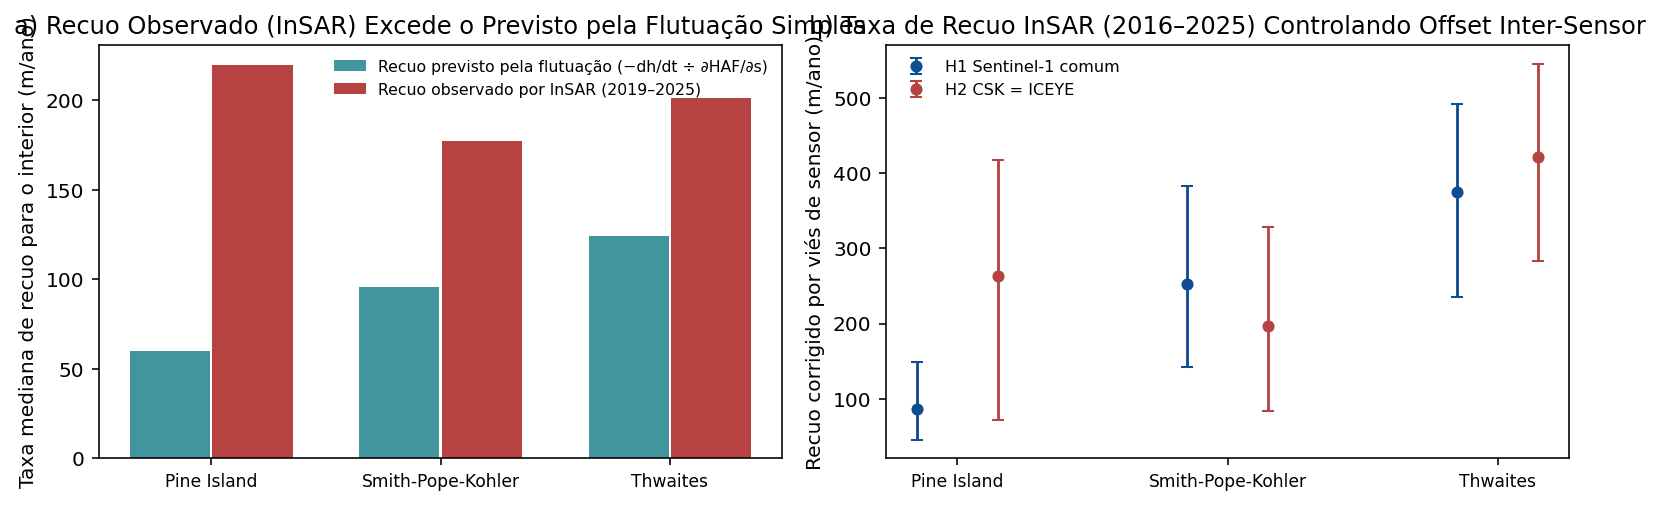

,n_linhas,haf_gl,dhdt,v_prev,v_obs,razao,razao_lo,razao_hi
geleira,,,,,,,,
Pine Island,135,17.00,-1.95,-59.73,-219.84,3.68,1.42,5.49
Smith-Pope-Kohler,165,20.97,-2.56,-95.87,-177.20,1.85,0.83,5.47
Thwaites,208,24.90,-2.01,-124.26,-201.11,1.62,0.82,2.74


In [2]:
# 2. Comparação entre Recuo da Linha de Aterramento Previsto pela Flutuação (HAF) e Observado por InSAR
fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.6))
x_g = np.arange(len(gl_prev))
ax[0].bar(x_g - 0.18, -gl_prev["v_prev"], width=0.35, color="#42949E", label="Recuo previsto pela flutuação (−dh/dt ÷ ∂HAF/∂s)")
ax[0].bar(x_g + 0.18, -gl_prev["v_obs"], width=0.35, color="#B64342", label="Recuo observado por InSAR (2019–2025)")
ax[0].set_xticks(x_g)
ax[0].set_xticklabels(gl_prev["geleira"], fontsize=8.5)
ax[0].set_ylabel("Taxa mediana de recuo para o interior (m/ano)")
ax[0].set_title("a) Recuo Observado (InSAR) Excede o Previsto pela Flutuação Simples")
ax[0].legend(frameon=False, fontsize=7.8)

for i, (hip, grp) in enumerate(gl_vies.groupby("hipotese")):
    col = "#0F4D92" if "H1" in hip else "#B64342"
    pos = np.arange(len(grp)) + (-0.15 if i == 0 else 0.15)
    ax[1].errorbar(pos, -grp["v_m_ano"], yerr=[-grp["v_m_ano"] - (-grp["hi"]), (-grp["lo"]) - (-grp["v_m_ano"])],
                   fmt="o", color=col, lw=1.4, ms=5, capsize=3, label=hip)
ax[1].set_xticks(range(3))
ax[1].set_xticklabels(["Pine Island", "Smith-Pope-Kohler", "Thwaites"], fontsize=8.5)
ax[1].set_ylabel("Recuo corrigido por viés de sensor (m/ano)")
ax[1].set_title("b) Taxa de Recuo InSAR (2016–2025) Controlando Offset Inter-Sensor")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

gl_prev[["geleira", "n_linhas", "haf_gl", "dhdt", "v_prev", "v_obs", "razao", "razao_lo", "razao_hi"]].set_index("geleira").round(2)

---
## 1. Resultados da Dinâmica de Fraturamento em Fótons ATL03 e Rugosidade ATL06 na Margem da TEIS

A tabela abaixo apresenta o teste Lagrangiano de previsão por advecção pura versus observação para a densidade de fendas no ATL03 (`melange_fendas_atl03_advecao.csv`) e para a rugosidade superficial no ATL06 (`melange_rugosidade_atl06_advecao.csv`), demonstrando que na RGT 5 ($97{,}3\%$ do domínio material revisto) a densidade observada ($2{,}74\text{ fendas/km}$) concorda dentro do intervalo de confiança com a prevista pelo transporte de gelo já fraturado ($2{,}99\text{ fendas/km}$), enquanto na RGT 1079 (par 1) há excesso localizado de $+0{,}82\text{ fendas/km}$ (IC 95%: $+0{,}41$ a $+1{,}11$):

In [3]:
print("=== FENDAS EM FÓTONS ATL03: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===")
print(mel_fendas.round(3).to_string(index=False))
print("\n=== RUGOSIDADE ATL06: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===")
mel_rug.set_index(["pop", "faixa"]).round(3)

=== FENDAS EM FÓTONS ATL03: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===
 rgt  par  km_2425_vistos  frac_vista  previsto  observado  obs_menos_prev     lo     hi  pass_1821  pass_2425
   5    1           72.60       0.973     2.994      2.741          -0.253 -1.331  1.007          5          4
1079    1           45.52       0.838     0.628      1.450           0.822  0.412  1.112          4          3
1079    2           18.40       1.000     3.894      0.217          -3.677 -6.869 -0.651          4          3

=== RUGOSIDADE ATL06: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===


n_alvo  frac_com_ref    obs  previsto  obs_menos_prev     lo     hi  faixa_2019_20  desl_medio_km
pop             faixa                                                                                                      
f_grosso ≥ 0,72 margem      1113         0.604  3.686     3.281           0.405 -0.555  2.031          2.565          6.165
                interior    4491         0.838  3.217     2.620           0.596  0.141  1.372          3.190          4.551
só coesas       margem       937         0.604  3.230     2.843           0.387 -0.357  1.759          2.439          6.105
                interior    4021         0.819  2.712     2.388           0.324 -0.055  0.915          2.908          4.559